In [1]:

print("Greenpod Labs - Avocado Classification")
print("Step 1 completed successfully!")


Greenpod Labs - Avocado Classification
Step 1 completed successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [3]:
import os

print(os.listdir("/content"))

['.config', 'Orange Dataset.zip', 'sample_data']


In [4]:
import zipfile
import os

zip_path = "/content/Orange Dataset.zip"
extract_path = "/content/avocado_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))

Dataset extracted successfully!
['train', 'test']


In [5]:
import os

base_path = "/content/avocado_dataset"

print("Train folders:", os.listdir(base_path + "/train"))
print("Test folders:", os.listdir(base_path + "/test"))

Train folders: ['canker', 'grenning', 'blackspot', 'fresh']
Test folders: ['canker', 'grenning', 'blackspot', 'fresh']


In [6]:
import os

base_path = "/content/avocado_dataset"

for split in ["train", "test"]:
    print(f"\n{split.upper()} dataset:")
    for category in os.listdir(os.path.join(base_path, split)):
        folder = os.path.join(base_path, split, category)
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
        ]
        print(category, ":", len(images), "images")


TRAIN dataset:
canker : 179 images
grenning : 347 images
blackspot : 184 images
fresh : 281 images

TEST dataset:
canker : 22 images
grenning : 22 images
blackspot : 22 images
fresh : 33 images


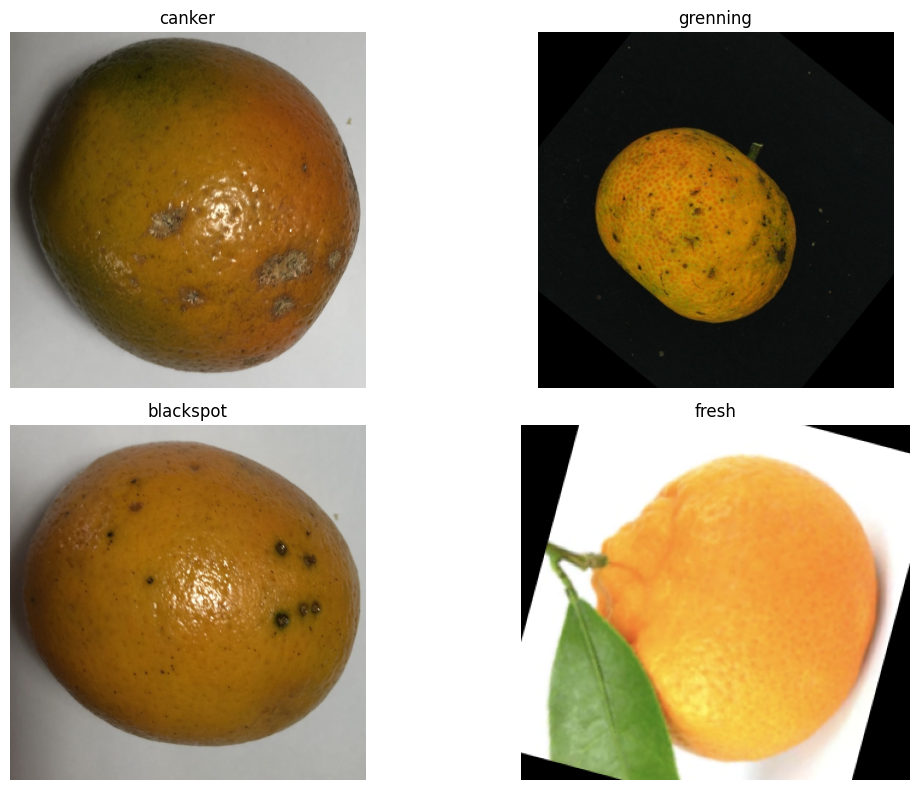

In [7]:
import os
import matplotlib.pyplot as plt
from PIL import Image

base_path = "/content/avocado_dataset/train"

classes = ["canker", "grenning", "blackspot", "fresh"]

plt.figure(figsize=(12, 8))

for i, category in enumerate(classes):
    folder = os.path.join(base_path, category)
    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    img = Image.open(os.path.join(folder, images[0])).convert("RGB")

    plt.subplot(2, 2, i + 1)
    plt.imshow(img)
    plt.title(category)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
from PIL import Image
import os

base_path = "/content/avocado_dataset/train"

for category in ["canker", "grenning", "blackspot", "fresh"]:
    folder = os.path.join(base_path, category)
    image_file = next(
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    )

    img = Image.open(os.path.join(folder, image_file))
    print(category, "image size:", img.size)

canker image size: (800, 800)
grenning image size: (800, 800)
blackspot image size: (800, 800)
fresh image size: (322, 294)


In [9]:
import tensorflow as tf

train_path = "/content/avocado_dataset/train"
test_path = "/content/avocado_dataset/test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(224, 224),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Classes:", train_ds.class_names)
print("Images resized and loaded successfully!")

Found 991 files belonging to 4 classes.
Found 99 files belonging to 4 classes.
Classes: ['blackspot', 'canker', 'fresh', 'grenning']
Images resized and loaded successfully!


In [10]:
import tensorflow as tf

# Use a pretrained MobileNetV2 model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    tf.keras.layers.Rescaling(1./127.5, offset=-1),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.8375 - loss: 0.4851 - val_accuracy: 0.9293 - val_loss: 0.1757
Epoch 2/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 34s 848ms/step - accuracy: 0.9627 - loss: 0.1213 - val_accuracy: 0.9394 - val_loss: 0.1455
Epoch 3/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 44s 938ms/step - accuracy: 0.9768 - loss: 0.0867 - val_accuracy: 0.9394 - val_loss: 0.1375
Epoch 4/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 27s 865ms/step - accuracy: 0.9859 - loss: 0.0640 - val_accuracy: 0.9495 - val_loss: 0.1348
Epoch 5/5
31/31 ━━━━━━━━━━━━━━━━━━━━ 27s 860ms/step - accuracy: 0.9828 - loss: 0.0591 - val_accuracy: 0.9495 - val_loss: 0.1311


4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 724ms/step
Test Accuracy: 0.9495
Macro Precision: 0.9436
Macro Recall: 0.9432
Macro F1-score: 0.9432

Classification Report:
              precision    recall  f1-score   support

   blackspot       0.90      0.86      0.88        22
      canker       0.87      0.91      0.89        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.95        99
   macro avg       0.94      0.94      0.94        99
weighted avg       0.95      0.95      0.95        99



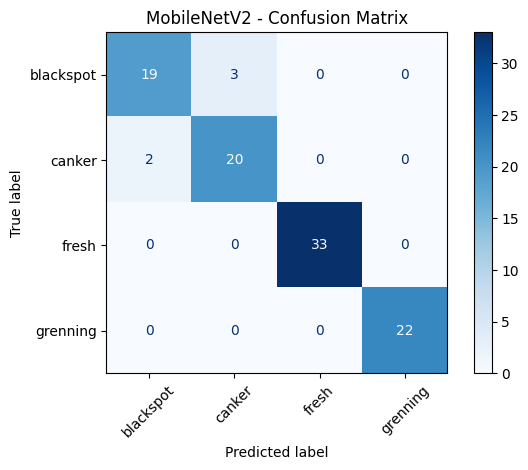

In [11]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print("Test Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro Precision:", round(precision_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Macro Recall:", round(recall_score(y_true, y_pred, average="macro", zero_division=0), 4))
print("Macro F1-score:", round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(train_ds.class_names))),
    target_names=train_ds.class_names,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=list(range(len(train_ds.class_names))),
    display_labels=train_ds.class_names,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [12]:
import os
import numpy as np
from PIL import Image
from skimage.feature import local_binary_pattern
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, f1_score

base = "/content/avocado_dataset"
classes = ["blackspot", "canker", "fresh", "grenning"]

def extract_features(path):
    img = Image.open(path).convert("RGB").resize((128, 128))
    rgb = np.array(img)

    # Colour histogram
    color_features = []
    for channel in range(3):
        hist, _ = np.histogram(
            rgb[:, :, channel], bins=16, range=(0, 256), density=True
        )
        color_features.extend(hist)

    # Texture features using LBP
    gray = np.array(img.convert("L"))
    lbp = local_binary_pattern(gray, P=8, R=1, method="uniform")
    texture_hist, _ = np.histogram(
        lbp, bins=np.arange(0, 11), range=(0, 10), density=True
    )

    return np.concatenate([color_features, texture_hist])

def load_features(split):
    X, y = [], []
    for label, category in enumerate(classes):
        folder = os.path.join(base, split, category)
        for filename in os.listdir(folder):
            if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
                path = os.path.join(folder, filename)
                try:
                    X.append(extract_features(path))
                    y.append(label)
                except Exception as e:
                    print("Skipped:", filename, e)
    return np.array(X), np.array(y)

X_train, y_train = load_features("train")
X_test, y_test = load_features("test")

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced")
)

svm_model.fit(X_train, y_train)
pred = svm_model.predict(X_test)

print("SVM Accuracy:", round(accuracy_score(y_test, pred), 4))
print("SVM Macro F1:", round(f1_score(y_test, pred, average="macro"), 4))
print("\nClassification Report:")
print(classification_report(y_test, pred, target_names=classes))

SVM Accuracy: 0.9697
SVM Macro F1: 0.9659

Classification Report:
              precision    recall  f1-score   support

   blackspot       0.95      0.91      0.93        22
      canker       0.91      0.95      0.93        22
       fresh       1.00      1.00      1.00        33
    grenning       1.00      1.00      1.00        22

    accuracy                           0.97        99
   macro avg       0.97      0.97      0.97        99
weighted avg       0.97      0.97      0.97        99



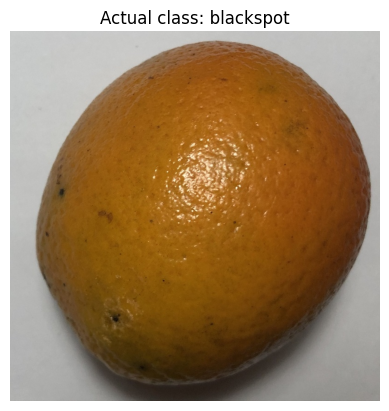

Actual class: blackspot
MobileNetV2 prediction: canker
SVM prediction: blackspot


In [13]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Select one image from the test dataset
sample_class = "blackspot"
folder = f"/content/avocado_dataset/test/{sample_class}"
sample_file = next(
    f for f in os.listdir(folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
)
sample_path = os.path.join(folder, sample_file)

# Display image
img = Image.open(sample_path).convert("RGB")
plt.imshow(img)
plt.title("Actual class: " + sample_class)
plt.axis("off")
plt.show()

# MobileNetV2 prediction
img_array = np.array(img.resize((224, 224)))
probabilities = model.predict(
    np.expand_dims(img_array, axis=0), verbose=0
)[0]
mobilenet_prediction = train_ds.class_names[np.argmax(probabilities)]

# SVM prediction
svm_prediction = classes[svm_model.predict(
    extract_features(sample_path).reshape(1, -1)
)[0]]

print("Actual class:", sample_class)
print("MobileNetV2 prediction:", mobilenet_prediction)
print("SVM prediction:", svm_prediction)

In [14]:
import joblib

# Save the SVM model
joblib.dump(svm_model, "/content/avocado_svm_model.pkl")

# Save the MobileNetV2 model
model.save("/content/avocado_mobilenet_model.keras")

print("Both models saved successfully!")

Both models saved successfully!
